In [1]:
# # rm(list = ls())
# # gc()
# library(MASS) # 多元正态分布
# library(Rcpp) # R链接c++语言
# # library(ggplot2) # 绘图
# # library(reshape2) # 数据融合
# library(compiler)
# # 平行计算
# library(foreach)
# library(iterators)
# library(parallel)
# library(doParallel) # 仅此一个也行
# sourceCpp('TestVCM.cpp')
# # sourceCpp('TestCPLRM3.cpp')
# # 矩阵计算函数(未除以n): angle_matrix()
# # 带Bootstrap的统计量仿真函数: testCPLRM()

# R.version

In [2]:
library(ggplot2)
library(survival)

library(survminer) # 之后不能安装ggsurvfit, 会改变依赖
# library(ggsurvfit)
library(patchwork)
library(ggsci)

In [3]:
data = read.csv('PBC_data/cirrhosis2.csv')
# remove missing value
del_names <- c('Chol', 'Copper', 'Platelets')
for (i in del_names){
    data = data[data[i] != '.',]
}

data = data[data$Status != 1, ] # 19(18) = 11 + 8 dead with liver transplant
data$Status[data$Status == 2] = 1

col_names <- colnames(data)


In [4]:
# data$Drug_fac <- factor(data$Drug, levels = c(1, 2), labels = c('D-penicillamine', 'Placebo'))
surv_obj <- Surv(time = data$Futime, event = data$Status)
fit <- survfit(surv_obj ~ Drug, data =data)

In [5]:
# lung = read.csv('dataset-68740.csv')
# su <- Surv(time = lung$time, event = ifelse(lung$status == 2, 1, 0))
# fit <- survfit(su ~ sex, data = lung)

TableGrob (3 x 1) "arrange": 3 grobs
  z     cells    name           grob
1 1 (1-1,1-1) arrange gtable[layout]
2 2 (2-2,1-1) arrange gtable[layout]
3 3 (3-3,1-1) arrange gtable[layout]

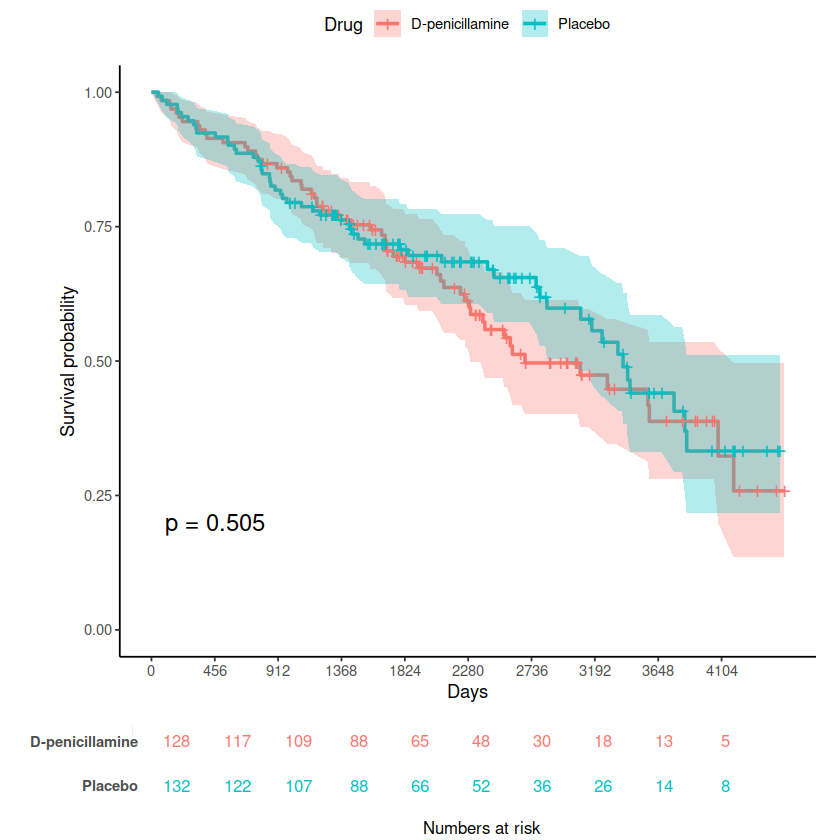

In [13]:
p_main = ggsurvplot(fit, 
#                     data = 
                    pval = TRUE, # 显示Log-rank检验p值
                   conf.int = TRUE, # 显示置信区间
                   risk.table = TRUE, # 添加风险表
                   risk.table.col="strata",
                   palette = 'nejm',
#                    surv.median.line = 'hv', # 添加中位生存时间线
                   xlab = 'Days',
                   legend.title = 'Drug',
                   legend.labs = c('D-penicillamine', 'Placebo')
            ) 
p_main

# ggsave('Results/', p_main, width = 12, height = 6)

In [19]:
ggsave('Results/123.pdf', p_main, width = 12, height = 8)

## 累积风险曲线

In [17]:
library(ggsurvfit)

ERROR: Error: package or namespace load failed for ‘ggsurvfit’ in loadNamespace(j <- i[[1L]], c(lib.loc, .libPaths()), versionCheck = vI[[j]]):
 namespace ‘survival’ 3.2-7 is already loaded, but >= 3.4.0 is required


In [18]:
p_sub <- ggsurvfit(fit, type = 'cumhaz') + add_risktable() + labs(title = 'Cumulative hazard function') #+ theme_classic(base_size = 10)
p_sub

ERROR: Error in ggsurvfit(fit, type = "cumhaz"): 没有"ggsurvfit"这个函数


In [ ]:
path_latex <- '..//3RealData/'
save_name <- 'asd'
# postscript(paste(path_latex, save_name, ".pdf", sep = ''), width = 8.0, height = 8.0)
p2 <- p_main + inset_element(p_sub, left = 0.6, bottom = 0.6, right = 0.95, top = 0.95)
p2
# ggsave("myplot.pdf", p2, width = 8, height = 8, units = "cm")

# dev.off()